In [1]:
!apt-get update -qq
!apt-get install -y g++ libopencv-dev libcurl4-openssl-dev

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
g++ is already the newest version (4:13.2.0-7ubuntu1).
g++ set to manually installed.
libcurl4-openssl-dev is already the newest version (8.5.0-2ubuntu10.16).
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0t64
  libatspi2.0-0t64 libavcodec-dev libavformat-dev libavutil-dev libcdparanoia0
  libcharls2 libdc1394-dev libdouble-conversion3 libevdev2 libexif-dev
  libexif-doc libexif12 libgdcm-dev libgdcm3.0t64 libgl2ps1.4 libglew2.2
  libgphoto2-6t64 libgphoto2-dev libgphoto2-l10n libgphoto2-port12t64
  libgstreamer-plugins-base1.0-0 libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  libgudev-1

In [2]:
%%writefile detect_faces.cpp
#include <iostream>
#include <vector>
#include <string>
#include <opencv2/opencv.hpp>
#include <opencv2/objdetect.hpp>
#include <curl/curl.h>

size_t WriteMemoryCallback(void* contents, size_t size, size_t nmemb, void* userp) {
    size_t realsize = size * nmemb;
    auto* mem = static_cast<std::vector<uchar>*>(userp);
    auto* ptr = static_cast<uchar*>(contents);
    mem->insert(mem->end(), ptr, ptr + realsize);
    return realsize;
}

std::vector<uchar> download(const std::string& url) {
    std::vector<uchar> data;
    CURL* curl = curl_easy_init();
    if (curl) {
        curl_easy_setopt(curl, CURLOPT_URL, url.c_str());
        curl_easy_setopt(curl, CURLOPT_WRITEFUNCTION, WriteMemoryCallback);
        curl_easy_setopt(curl, CURLOPT_WRITEDATA, &data);
        curl_easy_setopt(curl, CURLOPT_FOLLOWLOCATION, 1L);
        curl_easy_setopt(curl, CURLOPT_USERAGENT, "libcurl-agent/1.0");
        curl_easy_perform(curl);
        curl_easy_cleanup(curl);
    }
    return data;
}

// Загрузка: URL или локальный файл
cv::Mat loadImage(const std::string& source) {
    if (source.rfind("http", 0) == 0) {
        auto bytes = download(source);
        return cv::imdecode(bytes, cv::IMREAD_COLOR);
    }
    return cv::imread(source);
}

int main(int argc, char** argv) {
    // argv[1] - файл или URL, argv[2] - имя выходного файла
    std::string source = (argc > 1) ? argv[1]
        : "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg";
    std::string out_name = (argc > 2) ? argv[2] : "faces_detected.jpg";

    cv::Mat image = loadImage(source);
    if (image.empty()) {
        std::cerr << "Failed to load image from: " << source << std::endl;
        return 1;
    }
    std::cout << "Image: " << source << " (" << image.cols << "x" << image.rows << ")" << std::endl;

    cv::CascadeClassifier face_cascade, eye_cascade;
    if (!face_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml") ||
        !eye_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_eye.xml")) {
        std::cerr << "Cannot load cascades" << std::endl;
        return 1;
    }

    cv::Mat gray;
    cv::cvtColor(image, gray, cv::COLOR_BGR2GRAY);
    cv::equalizeHist(gray, gray);

    std::vector<cv::Rect> faces;
    face_cascade.detectMultiScale(gray, faces, 1.05, 5, 0, cv::Size(20, 20));

    int total_eyes = 0;
    int idx = 0;
    for (const auto& face : faces) {
        ++idx;
        cv::rectangle(image, face, cv::Scalar(0, 255, 0), 2);
        cv::putText(image, "Face " + std::to_string(idx),
                    cv::Point(face.x, std::max(face.y - 5, 15)),
                    cv::FONT_HERSHEY_SIMPLEX, 0.6, cv::Scalar(0, 255, 0), 2);

        // Глаза ищем только в верхних 60% лица
        cv::Mat roi = gray(face)(cv::Rect(0, 0, face.width, face.height * 6 / 10));
        std::vector<cv::Rect> eyes;
        eye_cascade.detectMultiScale(roi, eyes, 1.1, 10);
        total_eyes += (int)eyes.size();
        for (const auto& eye : eyes) {
            cv::rectangle(image,
                          cv::Rect(face.x + eye.x, face.y + eye.y, eye.width, eye.height),
                          cv::Scalar(255, 0, 0), 2);
        }
    }

    std::cout << "Detected faces: " << faces.size() << std::endl;
    std::cout << "Detected eyes:  " << total_eyes << std::endl;

    cv::imwrite(out_name, image);
    std::cout << "Saved: " << out_name << std::endl;
    return 0;
}

Writing detect_faces.cpp


In [3]:
!g++ detect_faces.cpp -o detect_faces $(pkg-config --cflags --libs opencv4 libcurl) -std=c++17

In [4]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving d738a59b5c4c8edce0356c03bc25f9b6.jpg to d738a59b5c4c8edce0356c03bc25f9b6.jpg
Saving f9a7ba47a25f17a87b6051dcd80bb1b8_ce_1920x1280x0x0_cropped_510x340.webp to f9a7ba47a25f17a87b6051dcd80bb1b8_ce_1920x1280x0x0_cropped_510x340.webp
Saving images.jpeg to images.jpeg
Saving studio-portrait-group-young-teenage-kids_23-2150162319.jpg.avif to studio-portrait-group-young-teenage-kids_23-2150162319.jpg.avif
Saving women-solidarity-concept-happy-young-female-team-stylish-staff-posing-wearing-jeans.jpg to women-solidarity-concept-happy-young-female-team-stylish-staff-posing-wearing-jeans.jpg
['d738a59b5c4c8edce0356c03bc25f9b6.jpg', 'f9a7ba47a25f17a87b6051dcd80bb1b8_ce_1920x1280x0x0_cropped_510x340.webp', 'images.jpeg', 'studio-portrait-group-young-teenage-kids_23-2150162319.jpg.avif', 'women-solidarity-concept-happy-young-female-team-stylish-staff-posing-wearing-jeans.jpg']


In [5]:
from PIL import Image

originals = [
    "d738a59b5c4c8edce0356c03bc25f9b6.jpg",
    "f9a7ba47a25f17a87b6051dcd80bb1b8_ce_1920x1280x0x0_cropped_510x340.webp",
    "images.jpeg",
    "studio-portrait-group-young-teenage-kids_23-2150162319.jpg.avif",
    "women-solidarity-concept-happy-young-female-team-stylish-staff-posing-wearing-jeans.jpg",
]

for i, name in enumerate(originals, start=1):
    try:
        img = Image.open(name).convert("RGB")
        img.thumbnail((1600, 1600))
        img.save(f"photo{i}.jpg", quality=95)
        print(f"photo{i}.jpg <- {name} ({img.width}x{img.height})")
    except Exception as e:
        print(f"ОШИБКА для {name}: {e}")

photo1.jpg <- d738a59b5c4c8edce0356c03bc25f9b6.jpg (735x913)
photo2.jpg <- f9a7ba47a25f17a87b6051dcd80bb1b8_ce_1920x1280x0x0_cropped_510x340.webp (510x340)
photo3.jpg <- images.jpeg (678x452)
photo4.jpg <- studio-portrait-group-young-teenage-kids_23-2150162319.jpg.avif (740x493)
photo5.jpg <- women-solidarity-concept-happy-young-female-team-stylish-staff-posing-wearing-jeans.jpg (1600x1067)


Image: photo1.jpg (735x913)
Detected faces: 6
Detected eyes:  0
Saved: result1.jpg


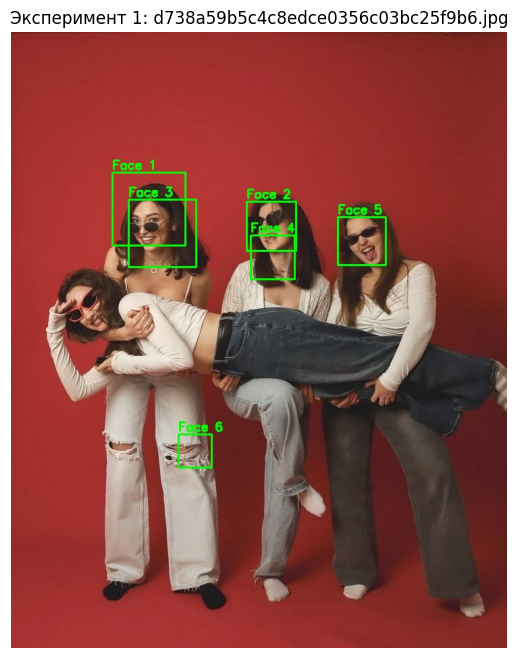

In [6]:
!./detect_faces photo1.jpg result1.jpg

import cv2
import matplotlib.pyplot as plt
img = cv2.cvtColor(cv2.imread('result1.jpg'), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title('Эксперимент 1: d738a59b5c4c8edce0356c03bc25f9b6.jpg')
plt.axis('off')
plt.show()

Image: photo2.jpg (510x340)
Detected faces: 1
Detected eyes:  0
Saved: result2.jpg


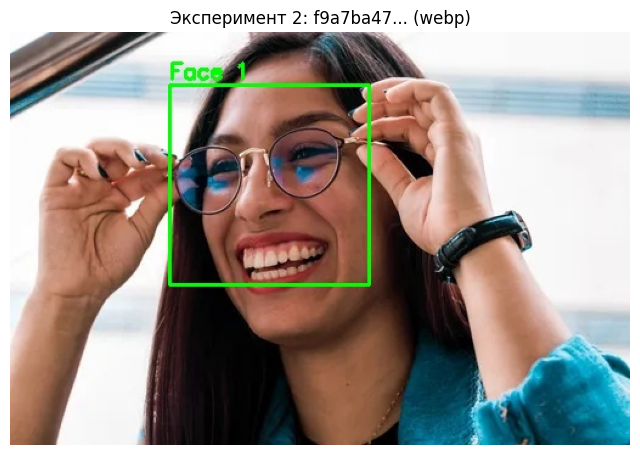

In [7]:
!./detect_faces photo2.jpg result2.jpg

import cv2
import matplotlib.pyplot as plt
img = cv2.cvtColor(cv2.imread('result2.jpg'), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title('Эксперимент 2: f9a7ba47... (webp)')
plt.axis('off')
plt.show()

Image: photo3.jpg (678x452)
Detected faces: 2
Detected eyes:  2
Saved: result3.jpg


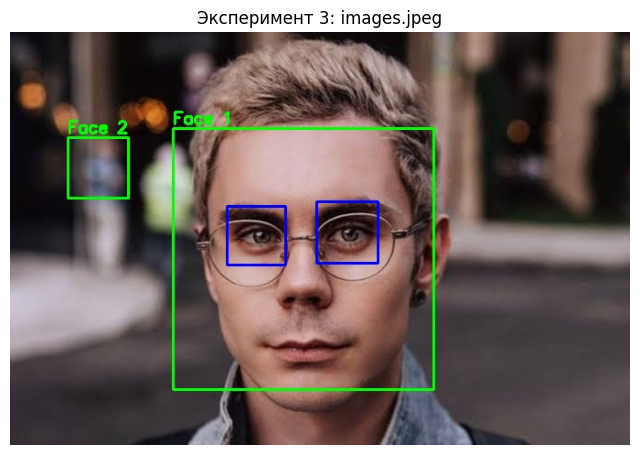

In [8]:
!./detect_faces photo3.jpg result3.jpg

import cv2
import matplotlib.pyplot as plt
img = cv2.cvtColor(cv2.imread('result3.jpg'), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title('Эксперимент 3: images.jpeg')
plt.axis('off')
plt.show()

Image: photo4.jpg (740x493)
Detected faces: 5
Detected eyes:  5
Saved: result4.jpg


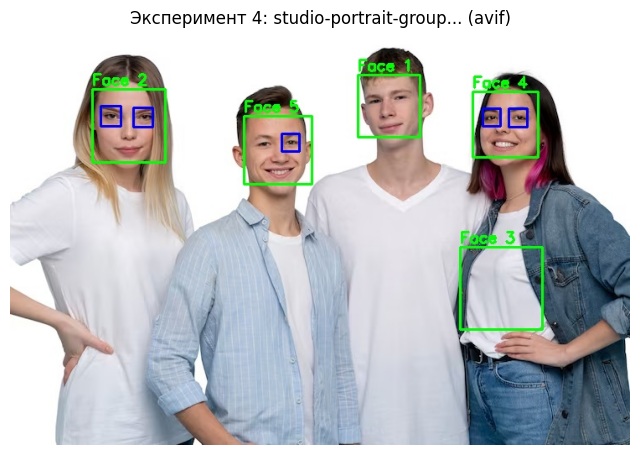

In [9]:
!./detect_faces photo4.jpg result4.jpg

import cv2
import matplotlib.pyplot as plt
img = cv2.cvtColor(cv2.imread('result4.jpg'), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title('Эксперимент 4: studio-portrait-group... (avif)')
plt.axis('off')
plt.show()

Image: photo5.jpg (1600x1067)
Detected faces: 11
Detected eyes:  0
Saved: result5.jpg


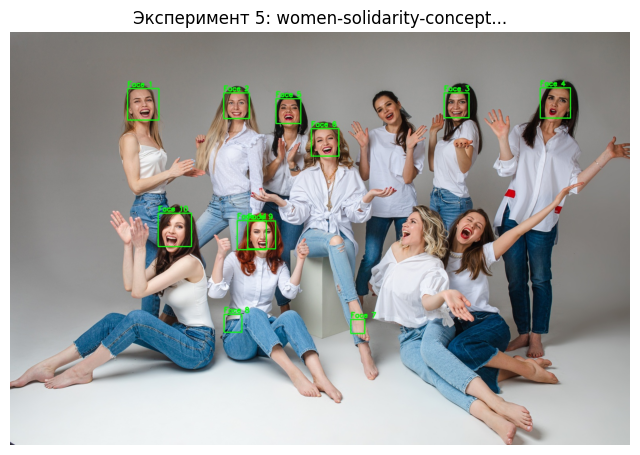

In [10]:
!./detect_faces photo5.jpg result5.jpg

import cv2
import matplotlib.pyplot as plt
img = cv2.cvtColor(cv2.imread('result5.jpg'), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title('Эксперимент 5: women-solidarity-concept...')
plt.axis('off')
plt.show()

## Сравнение

| № | Фото | Лиц на фото | Найдено каскадом | Глаз на фото | Найдено каскадом |
|---|------|-------------|------------------|--------------|------------------|
| 1 | Группа, один человек наклонён, солнцезащитные очки | 5 | 6 | 10 | 0 |
| 2 | Крупный план, очки, руки у лица | 1 | 1 | 2 | 0 |
| 3 | Портрет в очках, размытый фон | 1 | 2 | 2 | 2 |
| 4 | Группа из 4 человек, студийное фото | 4 | 5 | 8 | 5 |
| 5 | Большая группа | 11 | 11 | 22 | 0 |

## Почему результаты не совпадают

1. **Каскады ищут простые светлые и тёмные области** (например, глаза темнее лба).

2. **Ложные срабатывания.** Размытый фон (фото 3), джинсы и колени (фото 1, 5) и футболка (фото 4) случайно похожи на лицо по распределению светлых и тёмных пятен. Поэтому найденных лиц иногда больше, чем есть на фото.

3. **Дубли.** Если рамки совпадают лишь частично, они не объединяются в одну (фото 1, 5). Лицо считается дважды.

4. **Пропуски.** Каскад frontalface_default обучен на фронтальных лицах, поэтому наклонённые, повёрнутые и перекрытые лица находятся плохо (фото 1, 5). Поэтому число найденных лиц может случайно совпасть с реальным, хотя найдены не те (фото 5).

5. **Глаза находятся хуже лиц.** Они маленькие, и их закрывают очки с бликами, солнцезащитные очки, руки, ресницы (фото 1, 2). В группах лица занимают мало пикселей, и глаза в них совсем не находятся (фото 5, 0 из 22). Кроме того, глаза ищутся только в верхних 60% найденного лица. Если рамка лица неточная, глаза туда не попадают. Поэтому глаз найдено меньше, чем есть.

6. **Параметры.** scaleFactor, minNeighbors и minSize задают компромисс между пропусками и ложными срабатываниями. Я взяла minNeighbors=5 для лиц и 10 для глаз, это строгий порог, поэтому глаз находится мало.

**Вывод:** каскады Хаара дают приблизительную оценку и сильно зависят от ракурса, качества, размера лиц и наличия очков.